In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import randint
import warnings

from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV,RepeatedStratifiedKFold
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score,roc_curve, make_scorer, auc

# Data Preprocessing

In [ ]:
url = "https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE68086&format=file&file=GSE68086_TEP_data_matrix.txt.gz"

data_raw = pd.read_csv(url, sep='\t', compression='gzip')
data_raw.head()


,Unnamed: 0,3-Breast-Her2-ampl,8-Breast-WT,10-Breast-Her2-ampl,Breast-100,15-Breast-Her2-ampl,16-Breast-WT,21-Breast-WT,33-Breast-Her2-ampl,42-Breast-Her2-ampl,...,MGH-NSCLC-L20-TR500,MGH-NSCLC-L22-TR462,MGH-NSCLC-L23-TR524,MGH-NSCLC-L25-TR480,MGH-NSCLC-L39-TR519,MGH-NSCLC-L40-TR520,MGH-NSCLC-L51-TR521,MGH-NSCLC-L58-TR525,MGH-NSCLC-L59-TR522,MGH-NSCLC-L65-TR523
0,ENSG00000000003,0,0,0,0,17,0,0,0,0,...,0,5,10,9,0,0,0,0,0,0
1,ENSG00000000005,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,ENSG00000000419,44,14,16,8,9,0,139,108,55,...,2,41,40,15,1,0,13,0,0,10
3,ENSG00000000457,26,1,14,0,4,20,1,26,24,...,0,0,0,0,0,0,0,0,0,0
4,ENSG00000000460,81,98,18,17,0,20,144,26,97,...,23,1,6,22,30,0,1,50,6,2


In [ ]:
data_raw.shape

(57736, 286)

In [ ]:
data=data_raw.T
data.columns = data.iloc[0]
data = data[1:]
data.head()

Unnamed: 0,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,...,ENSG00000273481,ENSG00000273483,ENSG00000273484,ENSG00000273485,ENSG00000273486,ENSG00000273487,ENSG00000273488,ENSG00000273489,ENSG00000273492,ENSG00000273493
3-Breast-Her2-ampl,0,0,44,26,81,171,34,83,0,14,...,0,0,0,0,1,0,0,1,4,0
8-Breast-WT,0,0,14,1,98,99,0,107,0,5,...,0,0,0,0,0,0,0,0,0,0
10-Breast-Her2-ampl,0,0,16,14,18,25,0,62,4,13,...,0,0,0,0,0,0,0,0,0,0
Breast-100,0,0,8,0,17,4,0,19,0,0,...,0,0,0,0,0,0,0,0,0,0
15-Breast-Her2-ampl,17,0,9,4,0,49,0,40,0,10,...,0,0,0,0,0,0,0,0,0,0


## Column Annotation - Labels

I had to search this up by hand (manual addition)

In [ ]:
data['condition'] = ['healthy' if 'HD' in idx or 'Control' in idx or "Type-Unknown-3" in idx else 'cancer' for idx in data.index]
data['cancer_type'] =[
    "none" if 'HD' in idx or 'Control' in idx or "Type-Unknown-3" in idx else
    'GBM' if 'GBM' in idx or 'VU383Platelet-hiseq' in idx or 'VU394Platelet-hiseq' in idx else
    'NSCLC' if 'Lung' in idx or 'NSCLC' in idx else
    'CRC' if 'CRC' in idx or "Type-Unknown-5" in idx or "Type-Unknown-1" in idx else
    'PAAD' if 'Panc' in idx or "Type-Unknown-4" in idx else
    'BrCa' if 'Breast' in idx or 'BrCa' in idx or "Type-Unknown-6" in idx else
    'HBC' if 'Chol' in idx or 'Liver' in idx or 'HBC' in idx else
    'Other'
    for idx in data.index
]
data.head()

Unnamed: 0,ENSG00000000003,ENSG00000000005,ENSG00000000419,ENSG00000000457,ENSG00000000460,ENSG00000000938,ENSG00000000971,ENSG00000001036,ENSG00000001084,ENSG00000001167,...,ENSG00000273484,ENSG00000273485,ENSG00000273486,ENSG00000273487,ENSG00000273488,ENSG00000273489,ENSG00000273492,ENSG00000273493,condition,cancer_type
3-Breast-Her2-ampl,0,0,44,26,81,171,34,83,0,14,...,0,0,1,0,0,1,4,0,cancer,BrCa
8-Breast-WT,0,0,14,1,98,99,0,107,0,5,...,0,0,0,0,0,0,0,0,cancer,BrCa
10-Breast-Her2-ampl,0,0,16,14,18,25,0,62,4,13,...,0,0,0,0,0,0,0,0,cancer,BrCa
Breast-100,0,0,8,0,17,4,0,19,0,0,...,0,0,0,0,0,0,0,0,cancer,BrCa
15-Breast-Her2-ampl,17,0,9,4,0,49,0,40,0,10,...,0,0,0,0,0,0,0,0,cancer,BrCa


##Filtering

In [ ]:
#columns value ≥ 5
numeric_mask = (data.drop(columns=["condition", "cancer_type"], errors="ignore") >= 5) \
               .any(axis=0) \
               .reindex(data.columns, fill_value=False)

#keep the metadata columns
numeric_mask.loc[["condition", "cancer_type"]] = True

#subset
data_filtered = data.loc[:, numeric_mask]

print(data_filtered.shape)

(285, 16349)


In [ ]:
condition_counts = data_filtered['condition'].value_counts()
ancer_type_counts = data_filtered['cancer_type'].value_counts()

print(f"\nSamples per condition:{condition_counts}")
print(f"\nSamples per cancer_type:c{ancer_type_counts}")



Samples per condition:condition
cancer     230
healthy     55
Name: count, dtype: int64

Samples per cancer_type:ccancer_type
NSCLC    59
none     55
CRC      46
GBM      40
BrCa     39
PAAD     34
HBC      12
Name: count, dtype: int64


## Reduction and Split

Reduction based on the binary class

In [ ]:
min_c = data_filtered['condition'].value_counts()['healthy']

data_bin = data_filtered[data_filtered['condition'] == 'healthy']
data_bin = pd.concat([data_bin, data_filtered[data_filtered['condition'] == 'cancer'].sample(min_c, random_state=42)])
print(data_bin.shape)

(110, 16349)


multi reduction

In [ ]:
min_t = data_filtered['cancer_type'].value_counts()['HBC']

data_multi = pd.concat([
    data_filtered[data_filtered['cancer_type'] == ct].sample(min_t, random_state=42)
    for ct in data_filtered['cancer_type'].unique()
    #if ct != 'none'  #if pred only on six canc type, worked better for rf
])

print(data_multi.shape)

(84, 16349)


Splitting into test and train data

In [ ]:
x_bin = data_bin.drop(columns=['condition',"cancer_type"])
y_bin = data_bin['condition']

x_train_bin, x_test_bin, y_train_bin, y_test_bin = train_test_split(x_bin, y_bin, test_size=0.2, random_state=42, stratify=y_bin)

scaler = StandardScaler()
x_train_bin = scaler.fit_transform(x_train_bin)
x_test_bin = scaler.transform(x_test_bin)
#evtl scaling idk?

In [ ]:
x_multi = data_multi.drop(columns=['condition',"cancer_type"])
y_multi = data_multi['cancer_type']


x_train_multi, x_test_multi, y_train_multi, y_test_multi = train_test_split(x_multi, y_multi, test_size=0.2, random_state=42, stratify=y_multi)

scaler_multi = StandardScaler()
x_train_multi = scaler_multi.fit_transform(x_train_multi)
x_test_multi= scaler_multi.transform(x_test_multi)


# Random Forests

## Binary

In [ ]:
rf_bin = RandomForestClassifier( random_state=42)
rf_bin.fit(x_train_bin, y_train_bin)

y_pred_rf_train_bin = rf_bin.predict_proba(x_train_bin)[:, 1]
auc_rf_train_bin = roc_auc_score(y_train_bin, y_pred_rf_train_bin)
print(f"\nRF Binary Model AUC Score (train): {auc_rf_train_bin:.3f}")

y_pred_rf_test_bin = rf_bin.predict_proba(x_test_bin)[:, 1]
auc_rf_test_bin = roc_auc_score(y_test_bin, y_pred_rf_test_bin)
print(f"RF Binary Model AUC Score (test): {auc_rf_test_bin:.3f}")

y_pred_rf_train_bin = rf_bin.predict(x_train_bin)
acc_rf_train_bin = accuracy_score(y_train_bin, y_pred_rf_train_bin)
print(f"RF Binary Model Accuracy (train): {acc_rf_train_bin:.3f}")
y_pred_rf_test_bin = rf_bin.predict(x_test_bin)
acc_rf_test_bin = accuracy_score(y_test_bin, y_pred_rf_test_bin)
print(f"RF Binary Model Accuracy (test): {acc_rf_test_bin:.3f}")


RF Binary Model AUC Score (train): 1.000
RF Binary Model AUC Score (test): 0.963
RF Binary Model Accuracy (train): 1.000
RF Binary Model Accuracy (test): 0.864


## Multi

In [ ]:
rf_multi = RandomForestClassifier( random_state=42)
rf_multi.fit(x_train_multi, y_train_multi)

y_pred_multi = rf_multi.predict(x_train_multi)

acc = accuracy_score(y_train_multi, y_pred_multi)
print(f"Accuracy (train): {acc:.3f}")


y_pred_multi = rf_multi.predict(x_test_multi)

acc = accuracy_score(y_test_multi, y_pred_multi)
print(f"Accuracy (test): {acc:.3f}")

#print(classification_report(y_test_multi, y_pred_multi,zero_division=0))

Accuracy (train): 1.000
Accuracy (test): 0.353


## Feature Extraction

Binary RF- features

In [ ]:

importances_raw = rf_bin.feature_importances_
feature_names = x_bin.columns #feature_names from the original data

importances_df = pd.DataFrame({
    'Name': feature_names,
    'Importance': importances_raw
})

importances_df = importances_df.sort_values(by='Importance', ascending=False)
top_10_features_rf = importances_df.head(10)

print("Top 10 features for binary classification in Random Forest:")
print(top_10_features_rf)

Top 10 features for binary classification in Random Forest:
                  Name  Importance
12680  ENSG00000198851    0.013326
4329   ENSG00000122224    0.010358
11559  ENSG00000184922    0.009439
5474   ENSG00000133422    0.008507
7642   ENSG00000152601    0.008473
9734   ENSG00000168685    0.008067
1093   ENSG00000074966    0.007858
8241   ENSG00000159461    0.007446
10569  ENSG00000174917    0.007059
6636   ENSG00000142192    0.006429


Multiclass-RF features

In [ ]:
importances_raw_multi = rf_multi.feature_importances_
feature_names_multi = x_multi.columns
importances_df_multi = pd.DataFrame({
    'Name': feature_names_multi,
    'Importance': importances_raw_multi
})
importances_df_multi = importances_df_multi.sort_values(by='Importance', ascending=False)
top_10_features_rf_multi = importances_df_multi.head(10)

print("Top 10 features for multi-class classification (Random Forest .feature_importances_):")
print(top_10_features_rf_multi)

Top 10 features for multi-class classification (Random Forest .feature_importances_):
                  Name  Importance
2275   ENSG00000102898    0.004819
7742   ENSG00000153904    0.003803
13967  ENSG00000228651    0.003679
9249   ENSG00000166037    0.003669
213    ENSG00000010327    0.003228
9149   ENSG00000165502    0.003061
15493  ENSG00000255002    0.003048
3158   ENSG00000110651    0.003015
7048   ENSG00000145734    0.002963
9319   ENSG00000166432    0.002861


# PCLA

## Hyperparameter Optimization

In [ ]:
from sklearn.exceptions import FitFailedWarning
import warnings
warnings.filterwarnings("ignore", category=FitFailedWarning)

binary_pcla = Pipeline([
    ("pca", PCA(n_components=1, random_state=42)), #n_components is a placeholder here and will be overwritten by the optimization later
    ("clf", LogisticRegression(solver="liblinear", random_state=42))
])

# components <= min(sample_size, feature_size) -> even lower cause of cv
n_samples_per_fold = int(x_train_bin.shape[0] * (4/5))
max_components = min(n_samples_per_fold, x_train_bin.shape[1])


param_dist = {
    "pca__n_components": randint(1, max_components + 1)
}
rand_search = RandomizedSearchCV(
    estimator=binary_pcla,
    param_distributions=param_dist,
    n_iter=20,           # how many draws to try
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    random_state=42
)

rand_search.fit(x_train_bin, y_train_bin)

print(f"Best n_components: {rand_search.best_params_}")
print(f"Best CV AUC:      {rand_search.best_score_:.3f}")
best_n = rand_search.best_params_["pca__n_components"]

Best n_components: {'pca__n_components': 61}
Best CV AUC:      0.946


## Binary

In [ ]:
#Redeclaring the binary PCLA pipeline with the newly optimized hyperparameter for PCA
binary_pcla = Pipeline([
    ("pca", PCA(n_components=best_n, random_state=42)),
    ("clf", LogisticRegression(solver="liblinear", random_state=42))
])

In [ ]:
binary_pcla.fit(x_train_bin, y_train_bin)

Pipeline(steps=[('pca', PCA(n_components=61, random_state=42)),
                ('clf',
                 LogisticRegression(random_state=42, solver='liblinear'))])

In [ ]:
y_pred_pcla_train_bin = binary_pcla.predict_proba(x_train_bin)[:, 1]
auc_pcla_train_bin = roc_auc_score(y_train_bin, y_pred_pcla_train_bin)
print(f"\nPCLA Binary Model AUC Score (train): {auc_pcla_train_bin:.3f}")

y_pred_pcla_test_bin = binary_pcla.predict_proba(x_test_bin)[:, 1]
auc_pcla_test_bin = roc_auc_score(y_test_bin, y_pred_pcla_test_bin)
print(f"PCLA Binary Model AUC Score (test): {auc_pcla_test_bin:.3f}")


y_pred_pcla_test_bin = binary_pcla.predict(x_train_bin)
acc_pcla_test_bin = accuracy_score(y_train_bin, y_pred_pcla_test_bin)
print(f"PCLA Binary Model Accuracy (train): {acc_pcla_test_bin:.3f}")
y_pred_pcla_test_bin = binary_pcla.predict(x_test_bin)
acc_pcla_test_bin = accuracy_score(y_test_bin, y_pred_pcla_test_bin)
print(f"PCLA Binary Model Accuracy (test): {acc_pcla_test_bin:.3f}")


PCLA Binary Model AUC Score (train): 1.000
PCLA Binary Model AUC Score (test): 0.992
PCLA Binary Model Accuracy (train): 1.000
PCLA Binary Model Accuracy (test): 0.909


##Multiclass

In [ ]:
multi_pcla = Pipeline([
    ("pca", PCA(n_components=best_n, random_state=42)),
    ("clf", LogisticRegression( solver='lbfgs', max_iter=1000, random_state=42)) #Here we need to use a different solver for multiclass, max_iter made the warning go away :)
])

In [ ]:
multi_pcla.fit(x_train_multi, y_train_multi)

Pipeline(steps=[('pca', PCA(n_components=61, random_state=42)),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))])

In [ ]:
y_pred_multi = multi_pcla.predict(x_train_multi)

acc = accuracy_score(y_train_multi, y_pred_multi)
print(f"Accuracy (train): {acc:.3f}")

y_pred_multi_pcla = multi_pcla.predict(x_test_multi)

acc_pcla = accuracy_score(y_test_multi, y_pred_multi_pcla)
print(f"Accuracy (test): {acc_pcla:.3f}")

#print(classification_report(y_test_multi, y_pred_multi_pcla,zero_division=0))

Accuracy (train): 1.000
Accuracy (test): 0.294


## Feature Extraction

In [ ]:
pca_bin = binary_pcla.named_steps["pca"]
clf_bin = binary_pcla.named_steps["clf"]

pc_coefs_bin = clf_bin.coef_[0]
loadings_bin = pca_bin.components_
feat_weights_bin = loadings_bin.T.dot(pc_coefs_bin)

# Use the columns from the original x_bin DataFrame before scaling
# peaklist_bin = x_train_bin.columns # This line caused the error
peaklist_bin = x_bin.columns        # Use the original DataFrame columns

imp_df_bin = pd.DataFrame({
    "metabolite": peaklist_bin,
    "weight":      feat_weights_bin
})
imp_df_bin["abs_weight"] = imp_df_bin["weight"].abs()
imp_df_bin = imp_df_bin.sort_values("abs_weight", ascending=False)

print("Top 10 features for binary classification (PCLA):")
print(imp_df_bin.head(10))

Top 10 features for binary classification (PCLA):
            metabolite    weight  abs_weight
16192  ENSG00000269161  0.039208    0.039208
16062  ENSG00000266935  0.038105    0.038105
15406  ENSG00000254026 -0.037455    0.037455
12319  ENSG00000197140 -0.037118    0.037118
16044  ENSG00000266371  0.035995    0.035995
16316  ENSG00000272865 -0.035570    0.035570
11437  ENSG00000183763 -0.035311    0.035311
1492   ENSG00000088305 -0.035068    0.035068
2314   ENSG00000103154 -0.034865    0.034865
5273   ENSG00000131914  0.034815    0.034815


Multi class- PCLA features

In [ ]:
"""
Feature importance
1. Load the PCA and logistic regression objects from the final pipeline
2. Extracts the 1D array of logistic regression coefficients (one per principal component) and stores it.
3. Retrieves the PCA loadings (each row is a PC, each column corresponds to an original feature.
4. Multiplies the transpose of the loadings matrix by the PC coefficients to get a 1D array of weights—one per original metabolite
5. Creates a DataFrame with the metabolite names and their corresponding weights and sorting the DataFrame by absolute weight
"""

pca = multi_pcla.named_steps["pca"]
clf = multi_pcla.named_steps["clf"]

loadings = pca.components_
coefs = clf.coef_

feat_weights_all = []

for class_idx in range(coefs.shape[0]):
    class_coef = coefs[class_idx, :]
    feat_weights = np.dot(loadings.T, class_coef)
    feat_weights_all.append(np.abs(feat_weights))

avg_abs_weights = np.mean(feat_weights_all, axis=0)

peaklist = x_multi.columns
imp_df = pd.DataFrame({
    "metabolite": peaklist,
    "avg_abs_weight": avg_abs_weights
})

imp_df = imp_df.sort_values("avg_abs_weight", ascending=False)

print("Top 10 features for multi-class classification (PCLA):")
print(imp_df.head(10))

Top 10 features for multi-class classification (PCLA):
            metabolite  avg_abs_weight
342    ENSG00000022355        0.011094
13470  ENSG00000220785        0.011094
5917   ENSG00000136531        0.011094
4776   ENSG00000126785        0.011094
5792   ENSG00000135773        0.011094
15853  ENSG00000260475        0.011094
6213   ENSG00000138395        0.011094
15713  ENSG00000258689        0.011094
5864   ENSG00000136155        0.011075
14191  ENSG00000231666        0.011075


#Evaluation

##AUC CURVES- binary class

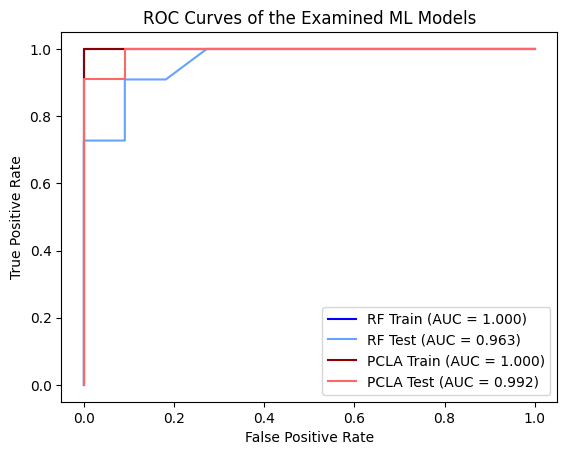

In [ ]:
y_prob_rf_test = rf_bin.predict_proba(x_test_bin)[:, 1]
fpr_rf_test, tpr_rf_test, _ = roc_curve(y_test_bin, y_prob_rf_test, pos_label='healthy')
auc_rf_test = auc(fpr_rf_test, tpr_rf_test)

y_prob_pcla_test = binary_pcla.predict_proba(x_test_bin)[:, 1]
fpr_pcla_test, tpr_pcla_test, _ = roc_curve(y_test_bin, y_prob_pcla_test, pos_label='healthy')
auc_pcla_test = auc(fpr_pcla_test, tpr_pcla_test)

y_prob_rf_train = rf_bin.predict_proba(x_train_bin)[:, 1]
fpr_rf_train, tpr_rf_train, _ = roc_curve(y_train_bin, y_prob_rf_train, pos_label='healthy')
auc_rf_train = auc(fpr_rf_train, tpr_rf_train)

y_prob_pcla_train = binary_pcla.predict_proba(x_train_bin)[:, 1]
fpr_pcla_train, tpr_pcla_train, _ = roc_curve(y_train_bin, y_prob_pcla_train, pos_label='healthy')
auc_pcla_train = auc(fpr_pcla_train, tpr_pcla_train)

plt.plot(fpr_rf_train, tpr_rf_train,color="blue" , label=f'RF Train (AUC = {auc_rf_train:.3f})')
plt.plot(fpr_rf_test, tpr_rf_test, color="#66A3FF", label=f'RF Test (AUC = {auc_rf_test:.3f})')
plt.plot(fpr_pcla_train, tpr_pcla_train,color ="darkred", label=f'PCLA Train (AUC = {auc_pcla_train:.3f})')
plt.plot(fpr_pcla_test, tpr_pcla_test,color="#FF6666", label=f'PCLA Test (AUC = {auc_pcla_test:.3f})')


plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves of the Examined ML Models')
plt.legend()
plt.show()

##Confusion matrix

##Random Forest

BIinary class- random forest confusion matrix

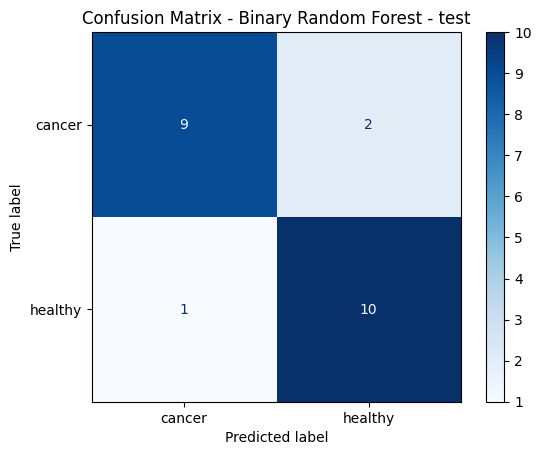

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred_rf_test_bin = rf_bin.predict(x_test_bin) #predictions for the binary test set

cm_bin = confusion_matrix(y_test_bin, y_pred_rf_test_bin, labels=rf_bin.classes_)
disp_bin = ConfusionMatrixDisplay(confusion_matrix=cm_bin, display_labels=rf_bin.classes_)
disp_bin.plot(cmap='Blues')
plt.title('Confusion Matrix - Binary Random Forest - test')
plt.show()

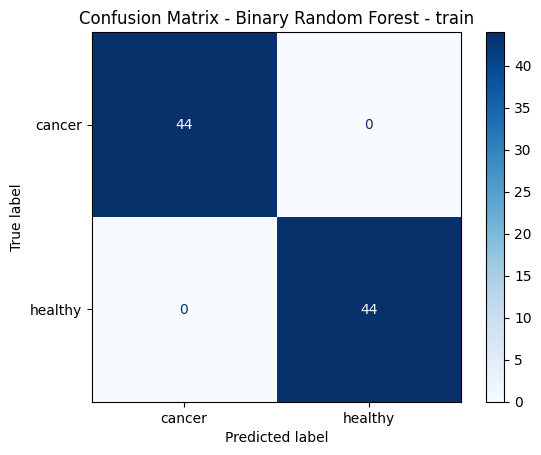

In [ ]:
y_pred_rf_train_bin = rf_bin.predict(x_train_bin) #predictions for the binary test set

cm_bin = confusion_matrix(y_train_bin, y_pred_rf_train_bin, labels=rf_bin.classes_)
disp_bin = ConfusionMatrixDisplay(confusion_matrix=cm_bin, display_labels=rf_bin.classes_)
disp_bin.plot(cmap='Blues')
plt.title('Confusion Matrix - Binary Random Forest - train')
plt.show()

In [ ]:
y_pred = rf_bin.predict(x_test_bin)
subtypes = data_filtered.loc[y_test_bin.index, 'cancer_type']

df = pd.DataFrame({
    'true': y_test_bin,
    'pred': y_pred,
    'subtype': subtypes
})

print("Classification result per subtype (RF):")
for subtype, group in df.groupby('subtype'):
    total = len(group)
    correct = (group['true'] == group['pred']).sum()
    print(f"{subtype}: {correct}/{total} ({correct / total:.0%})")

Classification result per subtype (RF):
BrCa: 2/2 (100%)
GBM: 3/5 (60%)
NSCLC: 4/4 (100%)
none: 10/11 (91%)


Multi-class- random forest confusion matrix

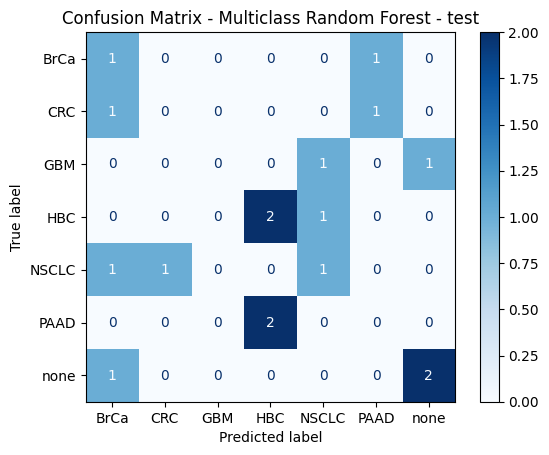

In [ ]:

y_pred_rf_test_multi = rf_multi.predict(x_test_multi)

cm_multi = confusion_matrix(y_test_multi, y_pred_rf_test_multi, labels=rf_multi.classes_)
disp_multi = ConfusionMatrixDisplay(confusion_matrix=cm_multi, display_labels=rf_multi.classes_)
disp_multi.plot(cmap='Blues')
plt.title('Confusion Matrix - Multiclass Random Forest - test')
plt.show()

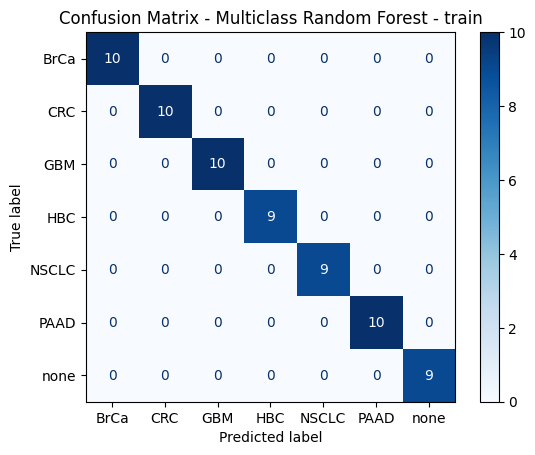

In [ ]:

y_pred_rf_test_multi = rf_multi.predict(x_train_multi)

cm_multi = confusion_matrix(y_train_multi, y_pred_rf_test_multi, labels=rf_multi.classes_)
disp_multi = ConfusionMatrixDisplay(confusion_matrix=cm_multi, display_labels=rf_multi.classes_)
disp_multi.plot(cmap='Blues')
plt.title('Confusion Matrix - Multiclass Random Forest - train')
plt.show()

##PCLA

Binary class- PCLA confusion matrix

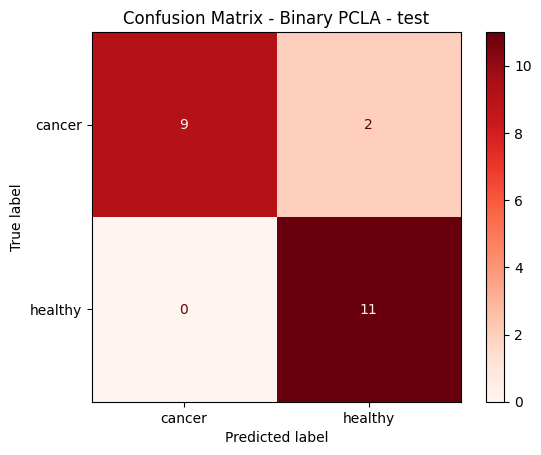

In [ ]:
y_pred_pcla_test_bin = binary_pcla.predict(x_test_bin)

cm_pcla_bin = confusion_matrix(y_test_bin, y_pred_pcla_test_bin, labels=binary_pcla.classes_)
disp_pcla_bin = ConfusionMatrixDisplay(confusion_matrix=cm_pcla_bin, display_labels=binary_pcla.classes_)
disp_pcla_bin.plot(cmap='Reds')
plt.title('Confusion Matrix - Binary PCLA - test')
plt.show()

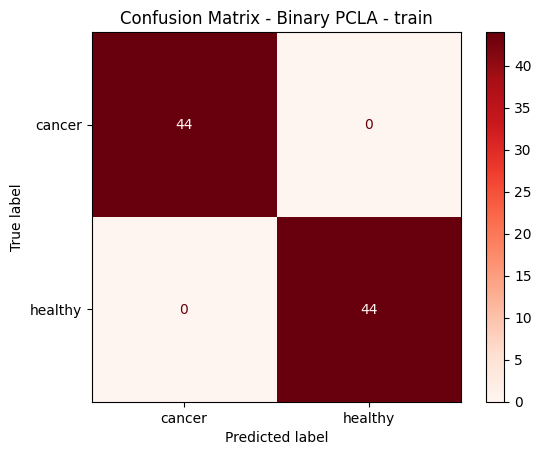

In [ ]:
y_pred_pcla_train_bin = binary_pcla.predict(x_train_bin)

cm_pcla_bin = confusion_matrix(y_train_bin, y_pred_pcla_train_bin, labels=binary_pcla.classes_)
disp_pcla_bin = ConfusionMatrixDisplay(confusion_matrix=cm_pcla_bin, display_labels=binary_pcla.classes_)
disp_pcla_bin.plot(cmap='Reds')
plt.title('Confusion Matrix - Binary PCLA - train')
plt.show()

In [ ]:
y_pred_pcla = binary_pcla.predict(x_test_bin)
subtypes = data_filtered.loc[y_test_bin.index, 'cancer_type']

df_pcla = pd.DataFrame({
    'true': y_test_bin,
    'pred': y_pred_pcla,
    'subtype': subtypes
})

print("Classification result per subtype (PCLA):")
for subtype, group in df_pcla.groupby('subtype'):
    total = len(group)
    correct = (group['true'] == group['pred']).sum()
    print(f"{subtype}: {correct}/{total} ({correct / total:.0%})")

Classification result per subtype (PCLA):
BrCa: 2/2 (100%)
GBM: 3/5 (60%)
NSCLC: 4/4 (100%)
none: 11/11 (100%)


Multi class- PCLA confusion matrix

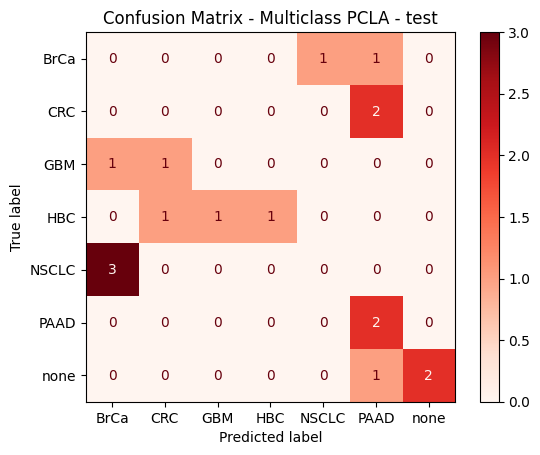

In [ ]:
y_pred_pcla_test_multi = multi_pcla.predict(x_test_multi)

#labels from multi_pcla model for consistency
cm_pcla_multi = confusion_matrix(y_test_multi, y_pred_pcla_test_multi, labels=multi_pcla.classes_)

disp_pcla_multi = ConfusionMatrixDisplay(confusion_matrix=cm_pcla_multi, display_labels=multi_pcla.classes_)
disp_pcla_multi.plot(cmap='Reds')
plt.title('Confusion Matrix - Multiclass PCLA - test')
plt.show()

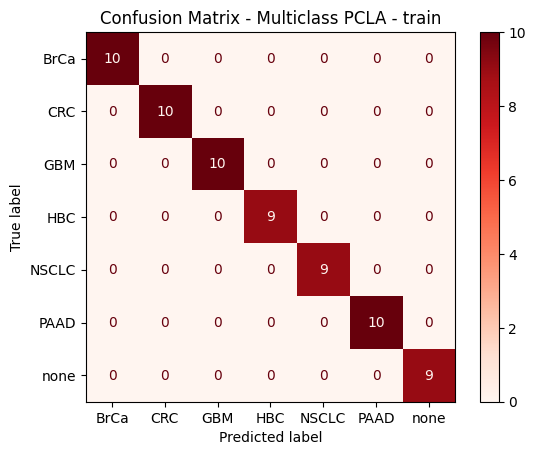

In [ ]:
y_pred_pcla_test_multi = multi_pcla.predict(x_train_multi)

#labels from multi_pcla model for consistency
cm_pcla_multi = confusion_matrix(y_train_multi, y_pred_pcla_test_multi, labels=multi_pcla.classes_)

disp_pcla_multi = ConfusionMatrixDisplay(confusion_matrix=cm_pcla_multi, display_labels=multi_pcla.classes_)
disp_pcla_multi.plot(cmap='Reds')
plt.title('Confusion Matrix - Multiclass PCLA - train')
plt.show()